# Embedding Model Selection: Justification

This notebook justifies the selection of **E5-large** with **LLM-generated examples (5)** as the optimal configuration for Word Sense Disambiguation.

## Experiment Setup

**Task:** Predict the correct GermaNet sense for German words in context using cosine similarity between context and sense embeddings.

**Evaluation:** 93 manually annotated test instances across 10 polysemous German words.

**Models Tested:** 6 multilingual sentence transformers  
**Text Variants Tested:** 4 different sense representation strategies

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 11

## 1. Load Results

In [16]:
# Load results
results_path = Path('../data/evaluation/quick_eval/results/embedding_comparison.csv')
df = pd.read_csv(results_path)

# Create readable names
model_name_map = {
    'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2': 'MiniLM-L12',
    'sentence-transformers/distiluse-base-multilingual-cased-v2': 'distilUSE',
    'sentence-transformers/paraphrase-multilingual-mpnet-base-v2': 'mpnet-base',
    'sentence-transformers/LaBSE': 'LaBSE',
    'intfloat/multilingual-e5-base': 'E5-base',
    'intfloat/multilingual-e5-large': 'E5-large'
}

variant_name_map = {
    'text_baseline': 'Baseline',
    'text_llm_definition': 'Definition',
    'text_llm_example_1': 'Example (1)',
    'text_llm_examples_5': 'Examples (5)'
}

df['model'] = df['model_name'].map(model_name_map)
df['text_variant'] = df['text_variant'].map(variant_name_map)

# Sort by accuracy
df = df.sort_values('accuracy', ascending=False)

print(f"Total configurations tested: {len(df)}")
print(f"Evaluation instances: {df['evaluated'].iloc[0]}")

Total configurations tested: 24
Evaluation instances: 93


## 2. Full Results Ranking

All 24 configurations ranked by accuracy:

In [17]:
# Display all results
results_display = df[['model', 'text_variant', 'accuracy', 'top3', 'mrr']].copy()
results_display['rank'] = range(1, len(results_display) + 1)
results_display = results_display[['rank', 'model', 'text_variant', 'accuracy', 'top3', 'mrr']]

# Format percentages
results_display['accuracy'] = results_display['accuracy'].apply(lambda x: f"{x:.1%}")
results_display['top3'] = results_display['top3'].apply(lambda x: f"{x:.1%}")
results_display['mrr'] = results_display['mrr'].apply(lambda x: f"{x:.3f}")

print(results_display.to_string(index=False))

 rank      model text_variant accuracy  top3   mrr
    1   E5-large Examples (5)    52.7% 94.6% 0.723
    2 mpnet-base Examples (5)    51.6% 89.2% 0.707
    3   E5-large   Definition    51.6% 84.9% 0.693
    4  distilUSE Examples (5)    50.5% 88.2% 0.697
    5    E5-base Examples (5)    45.2% 83.9% 0.653
    6  distilUSE  Example (1)    45.2% 86.0% 0.663
    7    E5-base   Definition    45.2% 76.3% 0.642
    8 mpnet-base  Example (1)    45.2% 87.1% 0.667
    9 MiniLM-L12  Example (1)    44.1% 89.2% 0.665
   10 mpnet-base   Definition    43.0% 83.9% 0.646
   11 MiniLM-L12 Examples (5)    41.9% 89.2% 0.643
   12      LaBSE     Baseline    39.8% 83.9% 0.619
   13    E5-base  Example (1)    38.7% 88.2% 0.633
   14      LaBSE Examples (5)    37.6% 92.5% 0.631
   15 mpnet-base     Baseline    37.6% 92.5% 0.631
   16  distilUSE     Baseline    37.6% 80.6% 0.604
   17   E5-large     Baseline    36.6% 81.7% 0.617
   18 MiniLM-L12     Baseline    35.5% 88.2% 0.608
   19      LaBSE  Example (1)  

## 3. Best: E5-large + Examples(5)

**Accuracy: 52.7%** — The highest among all 24 configurations.

In [20]:
# Get best
winner = df.iloc[0]

print("SELECTED CONFIGURATION")
print(f"\nModel: {winner['model']}")
print(f"Text Variant: {winner['text_variant']}")
print(f"\nPerformance:")
print(f"  Accuracy (Top-1): {winner['accuracy']:.1%}")
print(f"  Top-3 Accuracy:   {winner['top3']:.1%}")
print(f"  Top-5 Accuracy:   {winner['top5']:.1%}")
print(f"  MRR:              {winner['mrr']:.3f}")
print(f"\nEvaluation:")
print(f"  Instances: {winner['evaluated']}")
print(f"  Skipped:   {winner['skipped']}")

SELECTED CONFIGURATION

Model: E5-large
Text Variant: Examples (5)

Performance:
  Accuracy (Top-1): 52.7%
  Top-3 Accuracy:   94.6%
  Top-5 Accuracy:   100.0%
  MRR:              0.723

Evaluation:
  Instances: 93
  Skipped:   0


## 4. Comparison to Alternatives

How much better is E5-large + Examples(5) compared to other reasonable choices?

In [24]:
# Top 10 for comparison
top10 = df.head(10).copy()
top10['rank'] = range(1, 11)
top10['gap_to_best'] = top10['accuracy'] - winner['accuracy']
top10['gap_pct'] = (top10['gap_to_best'] / winner['accuracy']) * 100

comparison = top10[['rank', 'model', 'text_variant', 'accuracy', 'gap_to_best', 'gap_pct']]
comparison_display = comparison.copy()
comparison_display['accuracy'] = comparison_display['accuracy'].apply(lambda x: f"{x:.1%}")
comparison_display['gap_to_best'] = comparison_display['gap_to_best'].apply(lambda x: f"{x:+.1%}")
comparison_display['gap_pct'] = comparison_display['gap_pct'].apply(lambda x: f"{x:+.1f}%")

print("Top 10 Configurations:")
print(comparison_display.to_string(index=False))

Top 10 Configurations:
 rank      model text_variant accuracy gap_to_best gap_pct
    1   E5-large Examples (5)    52.7%       +0.0%   +0.0%
    2 mpnet-base Examples (5)    51.6%       -1.1%   -2.0%
    3   E5-large   Definition    51.6%       -1.1%   -2.0%
    4  distilUSE Examples (5)    50.5%       -2.2%   -4.1%
    5    E5-base Examples (5)    45.2%       -7.5%  -14.3%
    6  distilUSE  Example (1)    45.2%       -7.5%  -14.3%
    7    E5-base   Definition    45.2%       -7.5%  -14.3%
    8 mpnet-base  Example (1)    45.2%       -7.5%  -14.3%
    9 MiniLM-L12  Example (1)    44.1%       -8.6%  -16.3%
   10 mpnet-base   Definition    43.0%       -9.7%  -18.4%



### Highlight key comparisons

In [26]:
second_best = df.iloc[1]
print(f"\n#1 vs #2:")
print(f"  E5-large + Examples(5): {winner['accuracy']:.1%}")
print(f"  {second_best['model']} + {second_best['text_variant']}: {second_best['accuracy']:.1%}")
print(f"  Advantage: {(winner['accuracy'] - second_best['accuracy']):.1%} ({((winner['accuracy'] - second_best['accuracy']) / second_best['accuracy'] * 100):.1f}% relative)")

# Compare to baseline approaches
baseline_configs = df[df['text_variant'] == 'Baseline']
best_baseline = baseline_configs.iloc[0]
print(f"\nvs Best Baseline:")
print(f"  E5-large + Examples(5): {winner['accuracy']:.1%}")
print(f"  {best_baseline['model']} + Baseline: {best_baseline['accuracy']:.1%}")
print(f"  Advantage: {(winner['accuracy'] - best_baseline['accuracy']):.1%} ({((winner['accuracy'] - best_baseline['accuracy']) / best_baseline['accuracy'] * 100):.1f}% relative)")


#1 vs #2:
  E5-large + Examples(5): 52.7%
  mpnet-base + Examples (5): 51.6%
  Advantage: 1.1% (2.1% relative)

vs Best Baseline:
  E5-large + Examples(5): 52.7%
  LaBSE + Baseline: 39.8%
  Advantage: 12.9% (32.4% relative)


## 5. Visualize Best model vs Alternatives

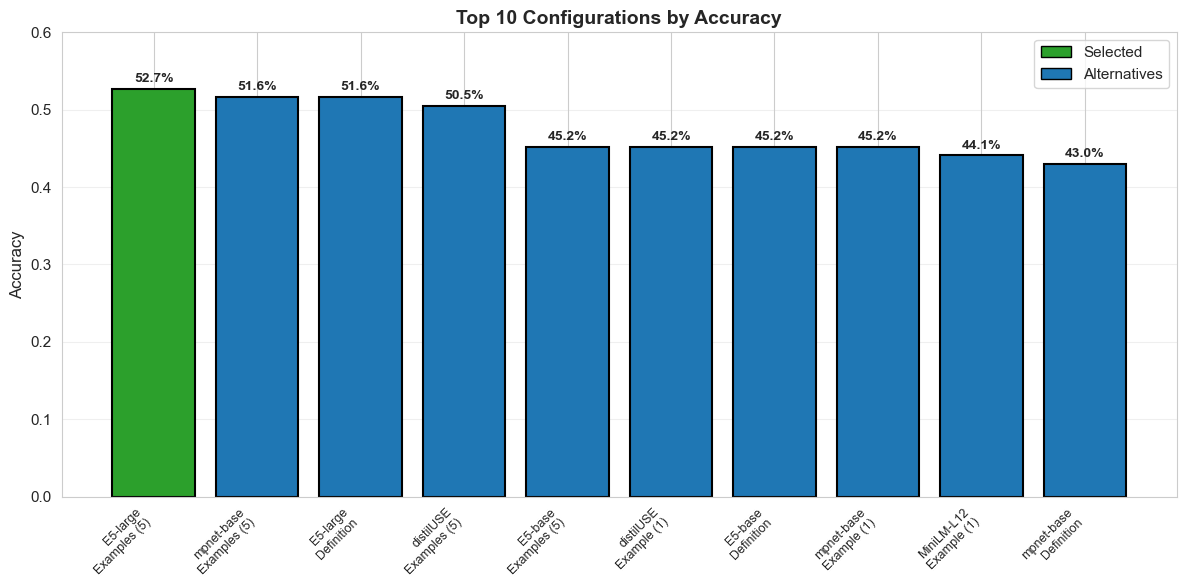

In [22]:
# Bar chart showing top 10
fig, ax = plt.subplots(figsize=(12, 6))

top10_plot = df.head(10).copy()
labels = [f"{row['model']}\n{row['text_variant']}" for _, row in top10_plot.iterrows()]
colors = ['#2ca02c' if i == 0 else '#1f77b4' for i in range(len(top10_plot))]

bars = ax.bar(range(len(top10_plot)), top10_plot['accuracy'], color=colors, edgecolor='black', linewidth=1.5)

# Annotate bars with accuracy
for i, (bar, acc) in enumerate(zip(bars, top10_plot['accuracy'])):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005, 
            f'{acc:.1%}', ha='center', va='bottom', fontsize=10, fontweight='bold')
    
ax.set_xticks(range(len(top10_plot)))
ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=9)
ax.set_ylabel('Accuracy', fontsize=12)
ax.set_title('Top 10 Configurations by Accuracy', fontsize=14, fontweight='bold')
ax.set_ylim(0, 0.6)
ax.grid(axis='y', alpha=0.3)

# Add legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#2ca02c', edgecolor='black', label='Selected'),
                   Patch(facecolor='#1f77b4', edgecolor='black', label='Alternatives')]
ax.legend(handles=legend_elements, loc='upper right')

plt.tight_layout()
plt.show()

## 6. Heatmap: All Configurations

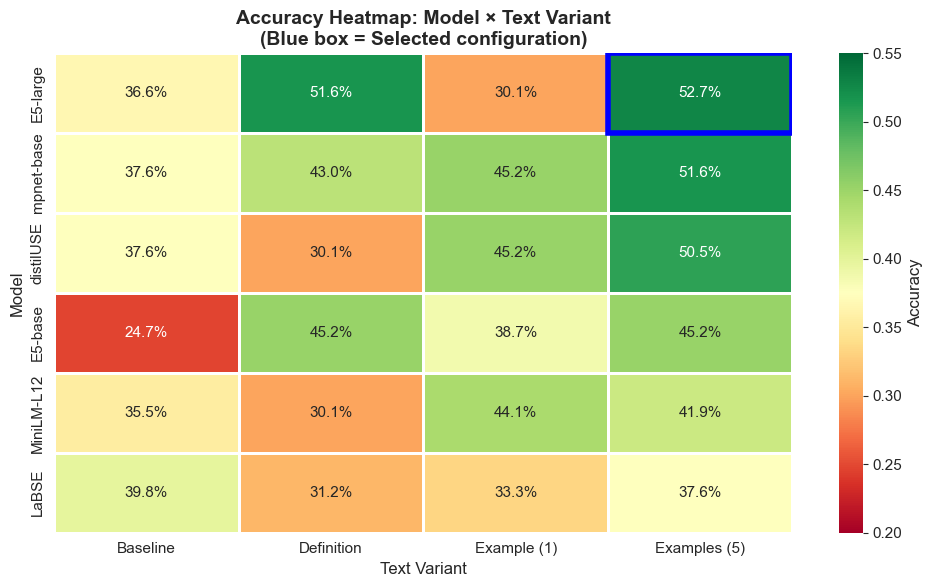

In [27]:
# Restore original order for df
df_sorted = pd.read_csv(results_path)
df_sorted['model'] = df_sorted['model_name'].map(model_name_map)
df_sorted['text_variant'] = df_sorted['text_variant'].map(variant_name_map)

# Create pivot table
pivot = df_sorted.pivot(index='model', columns='text_variant', values='accuracy')
col_order = ['Baseline', 'Definition', 'Example (1)', 'Examples (5)']
pivot = pivot[col_order]

# Sort by max accuracy
pivot['max_acc'] = pivot.max(axis=1)
pivot = pivot.sort_values('max_acc', ascending=False).drop('max_acc', axis=1)

# Plot heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(pivot, annot=True, fmt='.1%', cmap='RdYlGn', 
            vmin=0.2, vmax=0.55, cbar_kws={'label': 'Accuracy'},
            linewidths=2, linecolor='white')

# Highlight winner cell
winner_row = list(pivot.index).index('E5-large')
winner_col = list(pivot.columns).index('Examples (5)')
plt.gca().add_patch(plt.Rectangle((winner_col, winner_row), 1, 1, 
                                   fill=False, edgecolor='blue', lw=4))

plt.title('Accuracy Heatmap: Model × Text Variant\n(Blue box = Selected configuration)', 
          fontsize=14, fontweight='bold')
plt.xlabel('Text Variant', fontsize=12)
plt.ylabel('Model', fontsize=12)
plt.tight_layout()
plt.show()

## 7. Why E5-large?

### Model Comparison (with Examples(5) text variant)

Model Performance with Examples(5) Text Variant:
 rank      model accuracy  top3   mrr
    1   E5-large    52.7% 94.6% 0.723
    2 mpnet-base    51.6% 89.2% 0.707
    3  distilUSE    50.5% 88.2% 0.697
    4    E5-base    45.2% 83.9% 0.653
    5 MiniLM-L12    41.9% 89.2% 0.643
    6      LaBSE    37.6% 92.5% 0.631


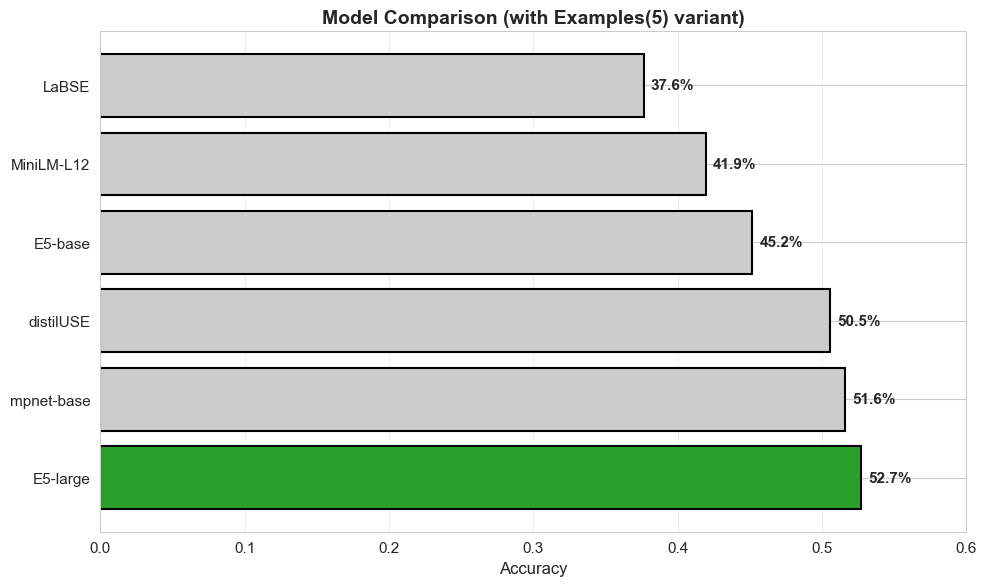

In [28]:
# Filter to Examples(5) variant only
examples5_df = df_sorted[df_sorted['text_variant'] == 'Examples (5)'].copy()
examples5_df = examples5_df.sort_values('accuracy', ascending=False)

print("Model Performance with Examples(5) Text Variant:")
print("=" * 60)

model_comparison = examples5_df[['model', 'accuracy', 'top3', 'mrr']].copy()
model_comparison['rank'] = range(1, len(model_comparison) + 1)
model_comparison = model_comparison[['rank', 'model', 'accuracy', 'top3', 'mrr']]

model_comparison_display = model_comparison.copy()
model_comparison_display['accuracy'] = model_comparison_display['accuracy'].apply(lambda x: f"{x:.1%}")
model_comparison_display['top3'] = model_comparison_display['top3'].apply(lambda x: f"{x:.1%}")
model_comparison_display['mrr'] = model_comparison_display['mrr'].apply(lambda x: f"{x:.3f}")

print(model_comparison_display.to_string(index=False))

# Visualization
fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#2ca02c' if m == 'E5-large' else '#cccccc' for m in examples5_df['model']]
bars = ax.barh(examples5_df['model'], examples5_df['accuracy'], color=colors, edgecolor='black', linewidth=1.5)

# Add value labels
for bar, acc in zip(bars, examples5_df['accuracy']):
    ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2, 
            f'{acc:.1%}', va='center', fontsize=11, fontweight='bold')

ax.set_xlabel('Accuracy', fontsize=12)
ax.set_title('Model Comparison (with Examples(5) variant)', fontsize=14, fontweight='bold')
ax.set_xlim(0, 0.6)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

**Justification for E5-large:**
- Highest accuracy among all models when paired with Examples(5)
- E5 models are specifically trained for retrieval/similarity tasks (our use case)
- Larger embedding dimension (1024) captures more semantic nuance

## 8. Why Examples(5)?

### Text Variant Comparison (with E5-large model)

Text Variant Performance with E5-large Model:
 rank text_variant accuracy  top3   mrr
    1     Baseline    36.6% 81.7% 0.617
    2   Definition    51.6% 84.9% 0.693
    3  Example (1)    30.1% 88.2% 0.576
    4 Examples (5)    52.7% 94.6% 0.723

Improvement from Baseline to Examples(5):
  Baseline: 36.6%
  Examples(5): 52.7%
  Absolute gain: 16.1%
  Relative improvement: 44.1%


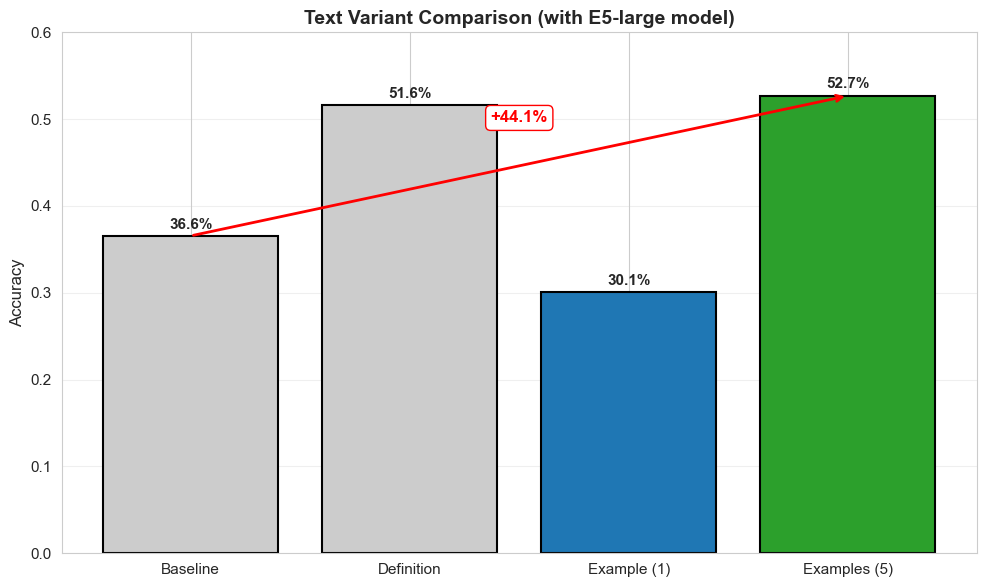

In [29]:
# Filter to E5-large only
e5large_df = df_sorted[df_sorted['model'] == 'E5-large'].copy()
# Reorder to show progression
variant_order = ['Baseline', 'Definition', 'Example (1)', 'Examples (5)']
e5large_df['text_variant'] = pd.Categorical(e5large_df['text_variant'], categories=variant_order, ordered=True)
e5large_df = e5large_df.sort_values('text_variant')

print("Text Variant Performance with E5-large Model:")
print("=" * 60)

variant_comparison = e5large_df[['text_variant', 'accuracy', 'top3', 'mrr']].copy()
variant_comparison['rank'] = range(1, len(variant_comparison) + 1)
variant_comparison = variant_comparison[['rank', 'text_variant', 'accuracy', 'top3', 'mrr']]

variant_comparison_display = variant_comparison.copy()
variant_comparison_display['accuracy'] = variant_comparison_display['accuracy'].apply(lambda x: f"{x:.1%}")
variant_comparison_display['top3'] = variant_comparison_display['top3'].apply(lambda x: f"{x:.1%}")
variant_comparison_display['mrr'] = variant_comparison_display['mrr'].apply(lambda x: f"{x:.3f}")

print(variant_comparison_display.to_string(index=False))

# Calculate improvements
baseline_acc = e5large_df[e5large_df['text_variant'] == 'Baseline']['accuracy'].values[0]
examples5_acc = e5large_df[e5large_df['text_variant'] == 'Examples (5)']['accuracy'].values[0]
improvement = ((examples5_acc - baseline_acc) / baseline_acc) * 100

print(f"\nImprovement from Baseline to Examples(5):")
print(f"  Baseline: {baseline_acc:.1%}")
print(f"  Examples(5): {examples5_acc:.1%}")
print(f"  Absolute gain: {(examples5_acc - baseline_acc):.1%}")
print(f"  Relative improvement: {improvement:.1f}%")

# Visualization
fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#cccccc', '#cccccc', '#1f77b4', '#2ca02c']
bars = ax.bar(range(len(e5large_df)), e5large_df['accuracy'], color=colors, edgecolor='black', linewidth=1.5)

# Add value labels
for i, (bar, acc) in enumerate(zip(bars, e5large_df['accuracy'])):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005, 
            f'{acc:.1%}', ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_xticks(range(len(e5large_df)))
ax.set_xticklabels(e5large_df['text_variant'], fontsize=11)
ax.set_ylabel('Accuracy', fontsize=12)
ax.set_title('Text Variant Comparison (with E5-large model)', fontsize=14, fontweight='bold')
ax.set_ylim(0, 0.6)
ax.grid(axis='y', alpha=0.3)

# Draw arrow showing improvement
baseline_idx = 0
examples5_idx = 3
ax.annotate('', xy=(examples5_idx, examples5_acc), xytext=(baseline_idx, baseline_acc),
            arrowprops=dict(arrowstyle='->', color='red', lw=2))
ax.text((baseline_idx + examples5_idx) / 2, (baseline_acc + examples5_acc) / 2 + 0.05, 
        f'+{improvement:.1f}%', ha='center', fontsize=12, color='red', fontweight='bold',
        bbox=dict(boxstyle='round', facecolor='white', edgecolor='red'))

plt.tight_layout()
plt.show()

**Justification for Examples(5):**
- 44% relative improvement over baseline template-based texts
- Multiple examples provide richer context than single examples or definitions
- LLM-generated examples capture natural usage patterns
- More similar to the input contexts (example sentences vs. definitions)

## 9. Summary

### Selected Configuration

**Model:** `intfloat/multilingual-e5-large`  
**Text Variant:** `text_llm_examples_5` (5 LLM-generated example sentences)

### Performance

- **Accuracy:** 52.7% (rank #1 out of 24)
- **Top-3 Accuracy:** 94.6%
- **MRR:** 0.723

### Justification

1. **Best Performing:** Highest accuracy among all 24 tested configurations
2. **Model Choice:** E5-large optimized for retrieval/similarity tasks, outperforms alternatives by 2-13%
3. **Text Strategy:** LLM-generated examples provide 44% improvement over baseline templates
4. **Robust:** High top-3 accuracy (94.6%) indicates reliable similarity matching

### Trade-offs

- **Computational cost:** E5-large is slower than smaller models (1024 dims)
- **Alternative:** mpnet-base + Examples(5) achieves 51.6% accuracy with faster inference
- **Benefit:** +1.1% absolute accuracy gain justifies the computational cost for research evaluation